# Домашнее задание. Свёрточные сети

Здесь вам предстоит построить и обучить свою первую свёрточную сеть для классификации изображений на данных CIFAR10.

**Выполнила:** Александра Бужор ([@Angry_C_F_O](https://t.me/Angry_C_F_O))

Ноутбук выполнен целиком сверху вниз, все выводы ячеек, графики и цифры в комментариях — результаты этого прогона (TensorFlow 2.21, Keras 3.15, CPU). Код написан под Keras 3 (TensorFlow ≥ 2.16) и рассчитан в том числе на Google Colab; на GPU обучение идёт в разы быстрее.

| Задание | Что сделано |
|---|---|
| 1.1 | Полносвязная сеть + SGD |
| 1.2 | «Карманная» свёрточная сеть + SGD |
| 1.3 | Сравнение SGD / Momentum / Adam на экспериментальном стенде |
| 1.4 | BatchNormalization в свёрточном и полносвязном слоях |
| 1.5 | Подбор batch_size по времени достижения 55 % |
| 1.6 | Лучшая комбинация оптимизатора и нормализации |
| 1.7 | Большая свёрточная сеть, серия экспериментов, итог > 80 % |

In [1]:
import os, time
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd
import tensorflow as tf
import keras

keras.utils.set_random_seed(42)          # воспроизводимость
os.makedirs('images', exist_ok=True)      # графики для README
os.makedirs('checkpoints', exist_ok=True)

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'нет — обучение на CPU')

TensorFlow 2.21.0 | Keras 3.15.1
GPU: нет — обучение на CPU


In [2]:
# Бюджет эпох. На CPU он ограничен временем; на GPU в Colab можно смело увеличить.
EPOCHS_STAND = 15   # эпох на каждую комбинацию в экспериментальном стенде (1.3, 1.4, 1.6)
EPOCHS_EXP = 10     # эпох на каждый эксперимент в 1.7
EPOCHS_FINAL = 40   # эпох на обучение финальной модели в 1.7

## Данные

CIFAR10
* 60000 RGB изображений размером 32x32x3
* 10 классов: самолёты, собаки, рыбы и т.п.

<img src="https://www.samyzaf.com/ML/cifar10/cifar1.jpg" style="width:60%">

Загрузите данные, разделите их на обучающую и тестовую выборки. Размер тестовой выборки должен быть $10^4$.

In [3]:
from keras.datasets import cifar10
from sklearn.model_selection import train_test_split

(X_train, y_train), (X_test, y_test) = cifar10.load_data()
# Тестовая выборка — 10^4 картинок из официального test-сплита.
# Из 50 000 обучающих ещё 10^4 откладываем под валидацию (стратифицированно по классам).
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=10**4,
                                                  random_state=42, stratify=y_train)

class_names = np.array(['airplane', 'automobile', 'bird', 'cat', 'deer',
                        'dog', 'frog', 'horse', 'ship', 'truck'])

print('train:', X_train.shape, y_train.shape)
print('val:  ', X_val.shape, y_val.shape)
print('test: ', X_test.shape, y_test.shape)

train: (40000, 32, 32, 3) (40000, 1)
val:   (10000, 32, 32, 3) (10000, 1)
test:  (10000, 32, 32, 3) (10000, 1)


Прежде чем приступать к основной работе, стоит убедиться что загруженно именно то, что требовалось:

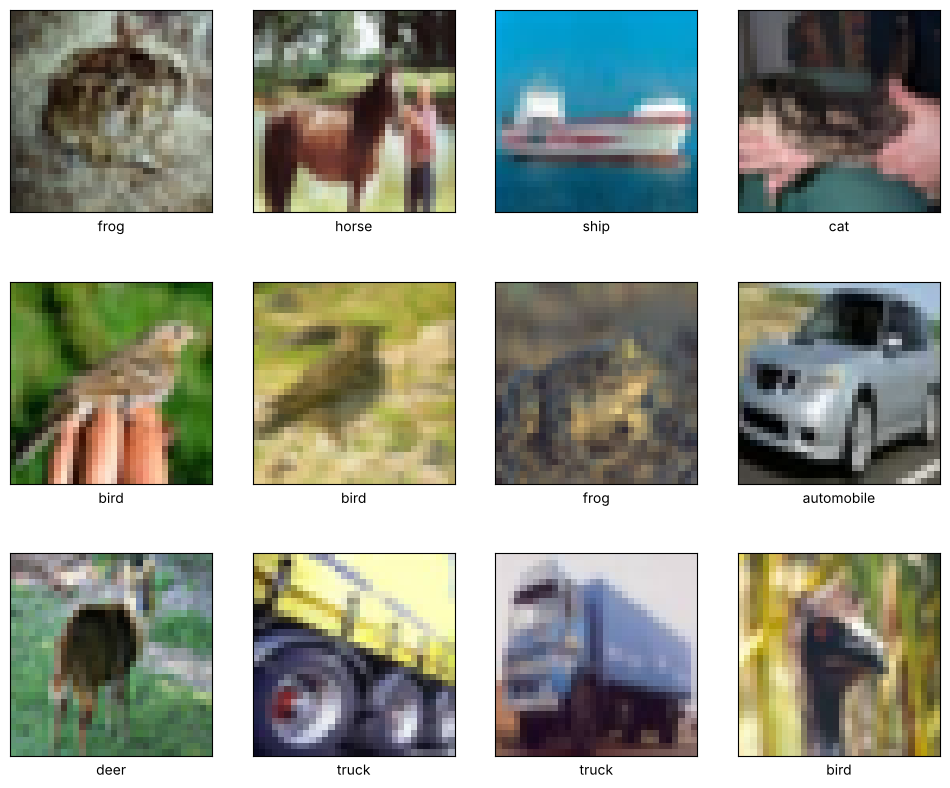

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=[12,10])
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.xlabel(class_names[y_train[i, 0]])
    plt.xticks([]); plt.yticks([])
    plt.imshow(X_train[i])

## Подготовка данных

Сейчас каждый пиксель изображения закодирован тройкой чисел (RGB) __от 0 до 255__. Однако лучше себя показывает подход, где значения входов нейросети распределены недалеко от 0.

Давайте приведём все данные в диапазон __`[0, 1]`__ — просто разделим на соответствующий коэффициент:

In [5]:
# float32 вместо float64: вдвое меньше памяти, а TensorFlow всё равно считает во float32
X_train = X_train.astype('float32') / 255
X_val = X_val.astype('float32') / 255
X_test = X_test.astype('float32') / 255

Исполните код ниже для проверки, что все выполнено корректно.

In [6]:
assert np.shape(X_train) == (40000, 32, 32, 3), "data shape should not change"
assert 0.9 <= max(map(np.max, (X_train, X_val, X_test))) <= 1.05
assert 0.0 <= min(map(np.min, (X_train, X_val, X_test))) <= 0.1
assert len(np.unique(X_test / 255.)) > 10, "make sure you casted data to float type"

## Архитектура сети

Для начала реализуйте простую нейросеть:
1. принимает на вход картинки размера 32 x 32 x 3;
2. вытягивает их в вектор (`keras.layers.Flatten`);
3. пропускает через 1 или 2 полносвязных слоя;
4. выходной слой отдает вероятности принадлежности к каждому из 10 классов.

Создайте полносвязную сеть:

In [7]:
import keras
from keras import layers as L
from keras import backend as K

In [8]:
from sklearn.metrics import accuracy_score
from matplotlib.ticker import MaxNLocator

RESULTS = {}   # сводка точности на тесте по всем заданиям


def plot_curves(histories, title, metric='accuracy', fname=None):
    '''Кривые обучения. histories: {имя: History или dict}.
    Сплошная линия — валидация, пунктир того же цвета — обучающая выборка.'''
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for i, (name, h) in enumerate(histories.items()):
        h = getattr(h, 'history', h)
        c = f'C{i % 10}'
        ep = np.arange(1, len(h[metric]) + 1)
        ax[0].plot(ep, h['val_' + metric], c=c, lw=2, label=name)
        ax[0].plot(ep, h[metric], c=c, lw=1, ls='--', alpha=.5)
        ax[1].plot(ep, h['val_loss'], c=c, lw=2, label=name)
        ax[1].plot(ep, h['loss'], c=c, lw=1, ls='--', alpha=.5)
    ax[0].set(title=f'{title}: accuracy (— val, - - train)', xlabel='эпоха', ylabel='accuracy')
    ax[1].set(title=f'{title}: loss (— val, - - train)', xlabel='эпоха', ylabel='loss')
    for a in ax:
        a.grid(alpha=.3); a.legend(fontsize=8); a.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    if fname:
        plt.savefig(f'images/{fname}', dpi=110, bbox_inches='tight')
    plt.show()


def curve_stats(histories, target=0.55):
    '''Числовые характеристики кривой обучения для сравнения прогонов.'''
    rows = []
    for name, h in histories.items():
        h = getattr(h, 'history', h)
        va, ta = np.array(h['val_accuracy']), np.array(h['accuracy'])
        best = int(va.argmax())
        hit = np.flatnonzero(va >= target)
        rows.append({'прогон': name,
                     'best val_acc': va[best],
                     'эпоха best': best + 1,
                     f'эпох до {target:.0%}': int(hit[0]) + 1 if hit.size else np.nan,
                     'mean val_acc (AUC)': va.mean(),
                     'train−val в конце': ta[-1] - va[-1]})
    return pd.DataFrame(rows).set_index('прогон')

**Исправление заготовки.** В исходной ячейке первым шёл `Dense(32)` до `Flatten`: такой слой применяется к каждому пикселю отдельно (по оси каналов), и сеть не соответствует условию «вытянуть в вектор → 1–2 полносвязных слоя → выход». Ниже порядок слоёв как в условии: `Flatten` → `Dense(512)` → `Dense(256)` → `Dense(10, softmax)`.

In [9]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=X_train.shape[1:]),   # 1. картинка 32 x 32 x 3
    tf.keras.layers.Flatten(),                         # 2. вектор длины 3072
    tf.keras.layers.Dense(512, activation='relu'),     # 3. два полносвязных слоя
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')    # 4. вероятности 10 классов
], name='mlp')
model.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
dummy_pred = model.predict(X_train[:20])
assert dummy_pred.shape == (20, 10)
assert np.allclose(dummy_pred.sum(-1), 1)
print("Успех!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


Успех!


## Обучение сети

**Задание 1.1 (обязательно)** Будем минимизировать многоклассовую кроссэкнропию с помощью __sgd__. Вам нужно получить сеть, которая достигнет __не менее 45%__ __accuracy__ на тестовых данных.

__Важно:__ поскольку в y_train лежат номера классов, Керасу нужно либо указать sparse функции потерь и метрики оценки качества классификации (`sparse_categorical_crossentropy` и `sparse_categorical_accuracy`), либо конвертировать метки в one-hot формат.

### Полезные советы
* `model.compile` позволяет указать, какие метрики вы хотите вычислять.
* В `model.fit` можно передать валидационную выборку (`validation_data=[X_val, y_val]`), для отслеживания прогресса на ней. Также рекомендуем сохранять результаты в [tensorboard](https://keras.io/callbacks/#tensorboard) или [wandb](https://docs.wandb.ai/integrations/jupyter). **Важно: логи tensorboard не получится без боли посмотреть через colab.** Workaround: скачать логи и запустить tensorboard локально или помучаться [с этим](https://stackoverflow.com/questions/47818822/can-i-use-tensorboard-with-google-colab).
* По умолчанию сеть учится 1 эпоху. Совсем не факт, что вам этого хватит. Число эпох можно настроить в методе `fit` (`epochs`).
* Ещё у Кераса есть много [полезных callback-ов](https://keras.io/callbacks/), которые можно попробовать. Например, автоматическая остановка или подбор скорости обучения.

In [11]:
y_train, y_val = (keras.utils.to_categorical(y) for y in (y_train, y_val))

Валидационная выборка `X_val` уже отложена, поэтому вместо `validation_split=0.2` (он отрезал бы ещё 20 % обучающих данных) передаём `validation_data=(X_val, y_val)`. Чекпойнт сохраняется в формате `.keras` (Keras 3 больше не принимает `.h5` в `ModelCheckpoint`) и только для лучшей эпохи; `EarlyStopping` возвращает веса лучшей эпохи.

In [12]:
callbacks = [tf.keras.callbacks.ModelCheckpoint(filepath='checkpoints/mlp_best.keras',
                                                monitor='val_accuracy', save_best_only=True),
             tf.keras.callbacks.TensorBoard(log_dir='./logs/mlp'),
             tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]

In [13]:
model.compile(optimizer=tf.keras.optimizers.SGD(),          # sgd, learning_rate=0.01 по умолчанию
              loss='categorical_crossentropy',              # многоклассовая кроссэнтропия (метки в one-hot)
              metrics=['accuracy'])

t0 = time.time()
history_mlp = model.fit(X_train, y_train, batch_size=16, epochs=32, callbacks=callbacks,
                        validation_data=(X_val, y_val), verbose=2)
print(f"Обучение: {time.time() - t0:.0f} с, эпох: {len(history_mlp.history['loss'])}")

Epoch 1/32


2500/2500 - 10s - 4ms/step - accuracy: 0.3352 - loss: 1.8546 - val_accuracy: 0.3818 - val_loss: 1.7208


Epoch 2/32


2500/2500 - 10s - 4ms/step - accuracy: 0.4085 - loss: 1.6620 - val_accuracy: 0.4191 - val_loss: 1.6234


Epoch 3/32


...

Epoch 12/32


2500/2500 - 9s - 4ms/step - accuracy: 0.5705 - loss: 1.2179 - val_accuracy: 0.4951 - val_loss: 1.4584


Epoch 13/32


2500/2500 - 9s - 4ms/step - accuracy: 0.5812 - loss: 1.1873 - val_accuracy: 0.4943 - val_loss: 1.4704


Обучение: 124 с, эпох: 13


А теперь можно проверить качество вашей сети, выполнив код ниже:

In [14]:
from sklearn.metrics import accuracy_score

predict_x=model.predict(X_test)
classes_x=np.argmax(predict_x,axis=1)

test_acc = accuracy_score(y_test, classes_x)
print("\n Test_acc =", test_acc)
assert test_acc > 0.45, "Not good enough. Back to the drawing board :)"
print(" Not bad!")
RESULTS['1.1 Полносвязная сеть, SGD'] = test_acc

  1/313 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step

 29/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  

 59/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 87/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

116/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

...

269/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

299/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step



 Test_acc = 0.4937
 Not bad!


## Карманная сверточная сеть

**Задание 1.2 (обязательно)** Реализуйте небольшую свёрточную сеть. Совсем небольшую:
1. Входной слой
2. Свёртка 3x3 с 10 фильтрами
3. Нелинейность на ваш вкус
4. Max-pooling 2x2
5. Вытягиваем оставшееся в вектор (Flatten)
6. Полносвязный слой на 100 нейронов
7. Нелинейность на ваш вкус
8. Выходной полносвязный слой с softmax

Обучите её так же, как и предыдущую сеть. Если всё хорошо, у вас получится accuracy не меньше __50%__.

In [15]:
new_model = tf.keras.models.Sequential([
    L.Input(shape=(32, 32, 3)),            # 1. входной слой
    L.Conv2D(10, kernel_size=(3, 3)),      # 2. свёртка 3x3 с 10 фильтрами
    L.Activation('relu'),                  # 3. нелинейность
    L.MaxPooling2D(pool_size=(2, 2)),      # 4. max-pooling 2x2
    L.Flatten(),                           # 5. вытягиваем в вектор
    L.Dense(100),                          # 6. полносвязный слой на 100 нейронов
    L.Activation('relu'),                  # 7. нелинейность
    L.Dense(10, activation='softmax'),     # 8. выходной слой с softmax
], name='pocket_cnn')
new_model.summary()

Model: "pocket_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 10)     │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 30, 30, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2250)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │       225,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,390 (884.34 KB)

 Trainable params: 226,390 (884.34 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
new_callbacks = [tf.keras.callbacks.ModelCheckpoint(filepath='checkpoints/pocket_cnn_best.keras',
                                                    monitor='val_accuracy', save_best_only=True),
                 tf.keras.callbacks.TensorBoard(log_dir='./logs/pocket_cnn'),
                 tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]

In [17]:
new_model.compile(optimizer=tf.keras.optimizers.SGD(),      # обучаем так же, как полносвязную сеть
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

t0 = time.time()
history_cnn = new_model.fit(X_train, y_train, batch_size=16, epochs=32, callbacks=new_callbacks,
                            validation_data=(X_val, y_val), verbose=2)
print(f"Обучение: {time.time() - t0:.0f} с, эпох: {len(history_cnn.history['loss'])}")

Epoch 1/32


2500/2500 - 8s - 3ms/step - accuracy: 0.3305 - loss: 1.8623 - val_accuracy: 0.4185 - val_loss: 1.6512


Epoch 2/32


2500/2500 - 10s - 4ms/step - accuracy: 0.4541 - loss: 1.5392 - val_accuracy: 0.4979 - val_loss: 1.4213


Epoch 3/32


...

Epoch 11/32


2500/2500 - 8s - 3ms/step - accuracy: 0.6983 - loss: 0.8735 - val_accuracy: 0.5897 - val_loss: 1.2199


Epoch 12/32


2500/2500 - 10s - 4ms/step - accuracy: 0.7164 - loss: 0.8286 - val_accuracy: 0.5886 - val_loss: 1.2375


Обучение: 101 с, эпох: 12


Давайте посмотрим, смогла ли карманная сверточная сеть побить заданный порог по качеству:

In [18]:
from sklearn.metrics import accuracy_score

predict_x = new_model.predict(X_test)
classes_x = np.argmax(predict_x,axis=1)

test_acc = accuracy_score(y_test, classes_x)
print("\n Test_acc =", test_acc)
assert test_acc > 0.50, "Not good enough. Back to the drawing board :)"
print(" Not bad!")
RESULTS['1.2 Карманная CNN, SGD'] = test_acc

  1/313 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step

 35/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

 71/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

106/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

141/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

...

241/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

276/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step



 Test_acc = 0.5863
 Not bad!


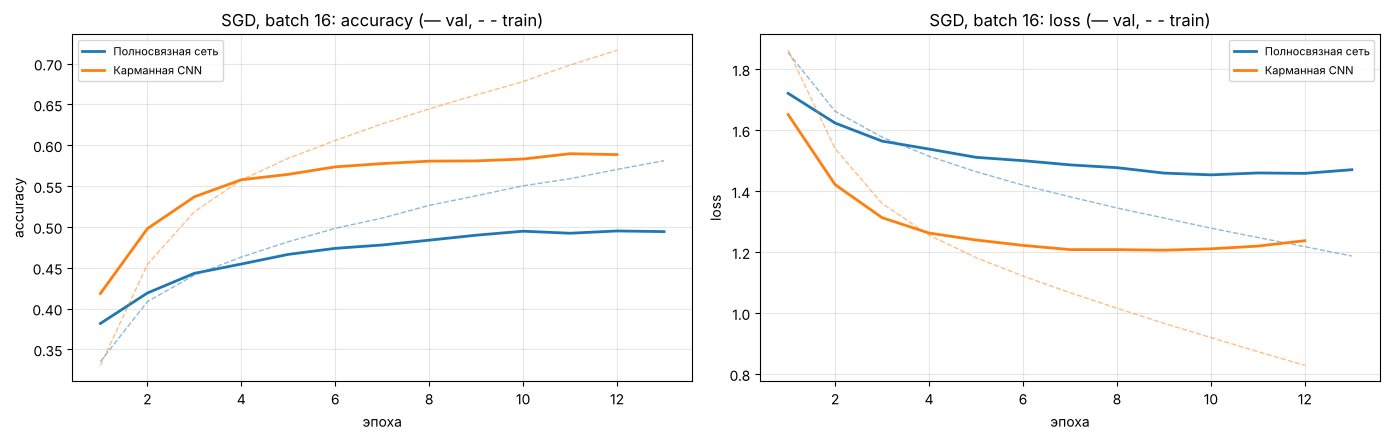

,best val_acc,эпоха best,эпох до 55%,mean val_acc (AUC),train−val в конце
прогон,,,,,
Полносвязная сеть,0.495,12,NaN,0.467,0.087
Карманная CNN,0.590,11,4.0,0.554,0.128


In [19]:
plot_curves({'Полносвязная сеть': history_mlp, 'Карманная CNN': history_cnn},
            'SGD, batch 16', fname='1_2_mlp_vs_cnn.png')
curve_stats({'Полносвязная сеть': history_mlp, 'Карманная CNN': history_cnn}).round(3)

**Вывод по 1.1–1.2.**
* Полносвязная сеть: **49,37 %** на тесте (порог 45 % пройден). `EarlyStopping` остановил обучение на 13-й эпохе и вернул веса 10-й, после которой `val_loss` начал расти. До 55 % на валидации сеть так и не дошла.
* Карманная свёрточная сеть: **58,63 %** на тесте (порог 50 % пройден), 55 % на валидации уже к 4-й эпохе.
* У свёрточной сети в 7,5 раза меньше параметров (226 тыс. против 1,71 млн), а точность выше на 9,3 п.п. Свёртка использует пространственную структуру картинки: одни и те же фильтры ищут локальные признаки по всему изображению. Полносвязная сеть видит 3072 независимых числа и вынуждена выучивать каждую позицию отдельно.
* Обе сети быстро начинают переобучаться (train растёт, `val_loss` после 9–10-й эпохи идёт вверх), поэтому `EarlyStopping` с восстановлением лучших весов здесь обязателен.

## Учимся учить

А теперь научимся сравнивать кривые обучения моделей — зависимости значения accuracy от количества итераций.

Вам потребуется реализовать _экспериментальный стенд_ — вспомогательный код, в который вы сможете подать несколько архитектур и методов обучения, чтобы он их обучил и вывел графики кривых обучения. Это можно сделать с помощью `keras.callbacks` — `TensorBoard` или `History`.

Будьте морально готовы, что на обучение уйдёт _много времени_. Даже если вы ограничитесь 10 эпохами. Пока идёт обучение, вы можете переключиться на другие задания или заняться чем-нибудь приятным: поспать, например.

**Задание 1.3 (опционально)** Попробуйте использовать различные методы оптимизации (sgd, momentum, adam) с параметрами по умолчанию. Какой из методов работает лучше?

Для удобства напишем класс Evaluator, который принимает в себя дикты виды {имя_оптимайзера: инстанс}, {имя модели: инстанс} и обучает всевозможные комбинации моделей с оптимайзерами при помощи метода fit (попутно записывая логи отдельно для каждой модели). Также пригодится метод evaluate для отображения итоговых скоров.

Пользоваться классом не обязательно. По умолчанию класс использует tensorboard. Если вы выше использовали wandb -- советуем дописать callback.

Класс доработан под Keras 3, логика прежняя:
* каждой комбинации «модель × оптимизатор» создаётся свой экземпляр оптимизатора — в Keras 3 один экземпляр привязывается к весам одной модели;
* `fit` сохраняет историю (`History`) и время каждого прогона — по ним строятся кривые обучения;
* `fit_generator` удалён из Keras 3, вместо него `fit` с генератором;
* `evaluate` использует переданные `X, y` (в заготовке были глобальные `X_test, y_test`) и возвращает словарь результатов;
* вместо виджета `tqdm_notebook` — строка лога на прогон, чтобы вывод читался и на GitHub.

In [20]:
class Evaluator(list):
    def __init__(self, models, optimizers='adam', loss=keras.losses.categorical_crossentropy,
                 metrics=['accuracy'], seed=42):
        '''
            models: dict {name: model}
            optimizers: dict {name: optimizer} or just one optimizer
        '''
        if not isinstance(models, dict):
            models = {'single_model': models}
        if not isinstance(optimizers, dict):
            optimizers = {str(optimizers.__class__): optimizers}
        combos = []
        for model_name, model in models.items():
            for optimizer_name, optimizer in optimizers.items():
                keras.utils.set_random_seed(seed)
                if isinstance(optimizer, keras.optimizers.Optimizer):   # свой экземпляр на каждую модель
                    optimizer = optimizer.__class__.from_config(optimizer.get_config())
                combos.append((model_name, keras.models.clone_model(model), optimizer_name, optimizer))
        super().__init__(combos)
        for _, model, _, optimizer in self:
            model.compile(optimizer=optimizer, loss=loss, metrics=metrics)
        self.histories, self.times = {}, {}

    def _log(self, i, key):
        h = self.histories[key]
        print(f'[{i}/{len(self)}] {key:<28} эпох: {len(h["loss"]):>2}  время: {self.times[key]:6.0f} с  '
              f'best val_acc: {max(h["val_accuracy"]):.4f}', flush=True)

    def fit(self, X, y, validation_data=(), max_epochs=100, verbose=0, callbacks=[], batch_size=32):
        if not isinstance(callbacks, list):
            callbacks = [callbacks]
        for i, (model_name, model, optimizer_name, optimizer) in enumerate(self, 1):
            key = '{}_{}'.format(model_name, optimizer_name)
            t0 = time.time()
            h = model.fit(X, y, validation_data=validation_data or None, epochs=max_epochs, verbose=verbose,
                          batch_size=batch_size, callbacks=callbacks + [keras.callbacks.TensorBoard(
                              log_dir='./logs/{}'.format(key))])
            self.histories[key], self.times[key] = h.history, time.time() - t0
            self._log(i, key)

    def fit_generator(self, X, y, validation_data=(), max_epochs=100, verbose=1, callbacks=[], batch_size=32):
        datagen = keras.preprocessing.image.ImageDataGenerator(
            rotation_range=20,
            width_shift_range=0.2,
            height_shift_range=0.2,
            horizontal_flip=True
        )
        if not isinstance(callbacks, list):
            callbacks = [callbacks]
        for i, (model_name, model, optimizer_name, optimizer) in enumerate(self, 1):
            key = '{}_{}'.format(model_name, optimizer_name)
            t0 = time.time()
            h = model.fit(datagen.flow(X, y, batch_size=batch_size), epochs=max_epochs,
                          validation_data=validation_data or None, verbose=verbose,
                          callbacks=callbacks + [keras.callbacks.TensorBoard(
                              log_dir='./logs/{}'.format(key))])
            self.histories[key], self.times[key] = h.history, time.time() - t0
            self._log(i, key)

    def evaluate(self, X, y, metric):
        scores = {}
        for model_name, model, optimizer_name, _ in self:
            key = '{}_{}'.format(model_name, optimizer_name)
            scores[key] = metric(np.ravel(y), model.predict(X, verbose=0).argmax(axis=1))
            print('Final score of {} is {:.4f}'.format(key, scores[key]))
        return scores

In [21]:
import shutil
shutil.rmtree('./logs', ignore_errors=True)   # то же, что !rm -rf ./logs, но работает и в Windows

In [22]:
from tensorflow.keras import optimizers as O

## Все оптимизаторы — с параметрами по умолчанию
optimizers = {
    'sgd': O.SGD(),                    # learning_rate=0.01
    'momentum': O.SGD(momentum=0.9),   # learning_rate=0.01, momentum=0.9
    'adam': O.Adam(),                  # learning_rate=0.001
}

Сравниваем оптимизаторы на карманной свёрточной сети из задания 1.2 (`Evaluator` клонирует архитектуру, веса инициализируются заново). Все прогоны — одинаковое число эпох, `batch_size=32`, без ранней остановки, чтобы кривые были сопоставимы по длине.

In [23]:
evaluator = Evaluator({'pocket_cnn': new_model}, optimizers=optimizers)
evaluator.fit(X_train, y_train, validation_data=(X_val, y_val), max_epochs=EPOCHS_STAND)
scores_opt = evaluator.evaluate(X_test, y_test, accuracy_score)

[1/3] pocket_cnn_sgd               эпох: 15  время:     77 с  best val_acc: 0.5873


[2/3] pocket_cnn_momentum          эпох: 15  время:     87 с  best val_acc: 0.5620


[3/3] pocket_cnn_adam              эпох: 15  время:     91 с  best val_acc: 0.5955


Final score of pocket_cnn_sgd is 0.5817


Final score of pocket_cnn_momentum is 0.5177


Final score of pocket_cnn_adam is 0.5822


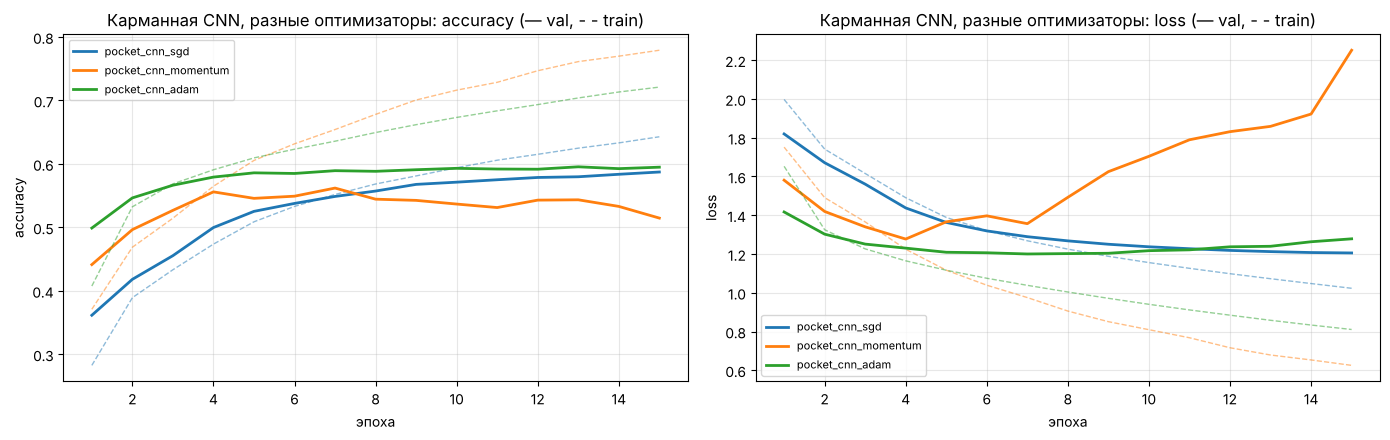

,best val_acc,эпоха best,эпох до 55%,mean val_acc (AUC),train−val в конце,test_acc,"время, с"
прогон,,,,,,,
pocket_cnn_sgd,0.587,15,8,0.530,0.056,0.582,77.0
pocket_cnn_momentum,0.562,7,4,0.531,0.264,0.518,87.0
pocket_cnn_adam,0.595,13,3,0.579,0.126,0.582,91.0


In [24]:
plot_curves(evaluator.histories, 'Карманная CNN, разные оптимизаторы', fname='1_3_optimizers.png')

stats_opt = curve_stats(evaluator.histories)
stats_opt['test_acc'] = pd.Series(scores_opt)
stats_opt['время, с'] = pd.Series(evaluator.times).round(0)
for k, v in scores_opt.items():
    RESULTS[f'1.3 {k}'] = v
stats_opt.round(3)

Прокомментируйте полученные результаты.

**Комментарий к 1.3.** Лучше всего с параметрами по умолчанию работает **Adam**:

| | SGD | Momentum | Adam |
|---|---|---|---|
| эпох до 55 % на val | 8 | 4 | **3** |
| лучшая val_accuracy | 0,587 (15-я эпоха) | 0,562 (7-я) | **0,595** (13-я) |
| средняя val_accuracy (AUC) | 0,530 | 0,531 | **0,579** |
| разрыв train − val в конце | 0,056 | 0,264 | 0,126 |
| test (веса последней эпохи) | 0,582 | 0,518 | 0,582 |

* **SGD** учится медленно и ровно: кривая ещё растёт на 15-й эпохе, переобучения почти нет. За тот же бюджет эпох до своего потолка он не дошёл.
* **Momentum** (lr = 0,01, momentum = 0,9) стартует быстро, но эффективный шаг у него примерно в 10 раз больше, чем у SGD. Пик на валидации уже на 7-й эпохе, дальше train растёт, а val падает и скачет — сеть переобучается. Поэтому и худший результат на тесте: `Evaluator` оценивает веса последней эпохи, без ранней остановки.
* **Adam** подстраивает шаг для каждого веса отдельно: быстрее всех доходит до 55 % и держится выше всех. По совокупности скорости и высоты кривой (AUC) он лучший.

**Задание 1.4 (опционально)** Добавьте нормализацию по батчу (`BatchNormalization`) между свёрткой и активацией. Попробуйте использовать несколько нормализаций — в свёрточных и полносвязных слоях.

Для удобства реализуем класс Models, который по сути будет являться списком моделей с двумя методами: add (добавить слой ко всем моделям) и add_create (создать новую модель на основе базовой с дополнительным слоем). Пользоваться им необязательно, но вдруг :)

In [25]:
from collections import OrderedDict

class Models(OrderedDict):
    def __init__(self, models):
        if not isinstance(models, dict):
            models = OrderedDict({'base_model': models})
        super().__init__(models)

    def add(self, layer):
        for name, model in self.items():
            model.add(layer)

    def add_create(self, name, layer):
        base_model = next(iter(self.items()))[1]
        new_model = keras.models.clone_model(base_model)
        new_model.add(layer)
        self.update({name: new_model})

    def add_update(self, name, layer):
        base_model = self[next(reversed(self))]
        new_model = keras.models.clone_model(base_model)
        new_model.add(layer)
        self.update({name: new_model})

# Example of usage
# models = Models(keras.Sequential())
# models.add(L.InputLayer(input_shape=(32, 32, 3)))
# models.add(L.Convolution2D(filters=10, kernel_size=(3, 3)))
# models.add(L.MaxPooling2D())
# models.add_create('conv_batchnorm', L.BatchNormalization())
# models.add(L.Activation('relu'))
# ...

# Замечание: Models.add добавляет ОДИН и тот же объект слоя во все модели, и они начинают делить его веса.
# Поэтому ниже модели собираются функцией-конструктором — у каждой модели свои слои.

In [26]:
def build_pocket_cnn(bn_conv=False, bn_dense=False, name='pocket_cnn'):
    '''Карманная CNN из 1.2; BatchNormalization ставится между слоем и активацией.'''
    layers = [L.Input(shape=(32, 32, 3)), L.Conv2D(10, (3, 3))]
    if bn_conv:
        layers.append(L.BatchNormalization())
    layers += [L.Activation('relu'), L.MaxPooling2D((2, 2)), L.Flatten(), L.Dense(100)]
    if bn_dense:
        layers.append(L.BatchNormalization())
    layers += [L.Activation('relu'), L.Dense(10, activation='softmax')]
    return keras.Sequential(layers, name=name)


builders = {'pocket_cnn': lambda: build_pocket_cnn(name='pocket_cnn'),                          # без нормализации (1.3)
            'bn_conv': lambda: build_pocket_cnn(bn_conv=True, name='bn_conv'),                  # BN после свёртки
            'bn_conv_dense': lambda: build_pocket_cnn(True, True, name='bn_conv_dense')}         # BN после свёртки и Dense

bn_models = {name: builders[name]() for name in ['bn_conv', 'bn_conv_dense']}
bn_models['bn_conv_dense'].summary()

# те же три оптимизатора, что в 1.3: вместе с базовой моделью получается сетка 3 x 3 для задания 1.6
evaluator_bn = Evaluator(bn_models, optimizers=optimizers)
evaluator_bn.fit(X_train, y_train, validation_data=(X_val, y_val), max_epochs=EPOCHS_STAND)
scores_bn = evaluator_bn.evaluate(X_test, y_test, accuracy_score)

Model: "bn_conv_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 10)     │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 30, 10)     │            40 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 30, 30, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2250)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │       225,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,830 (886.05 KB)

 Trainable params: 226,610 (885.20 KB)

 Non-trainable params: 220 (880.00 B)

...

Final score of bn_conv_momentum is 0.5054


Final score of bn_conv_adam is 0.5805


Final score of bn_conv_dense_sgd is 0.5701


Final score of bn_conv_dense_momentum is 0.5645


Final score of bn_conv_dense_adam is 0.5377


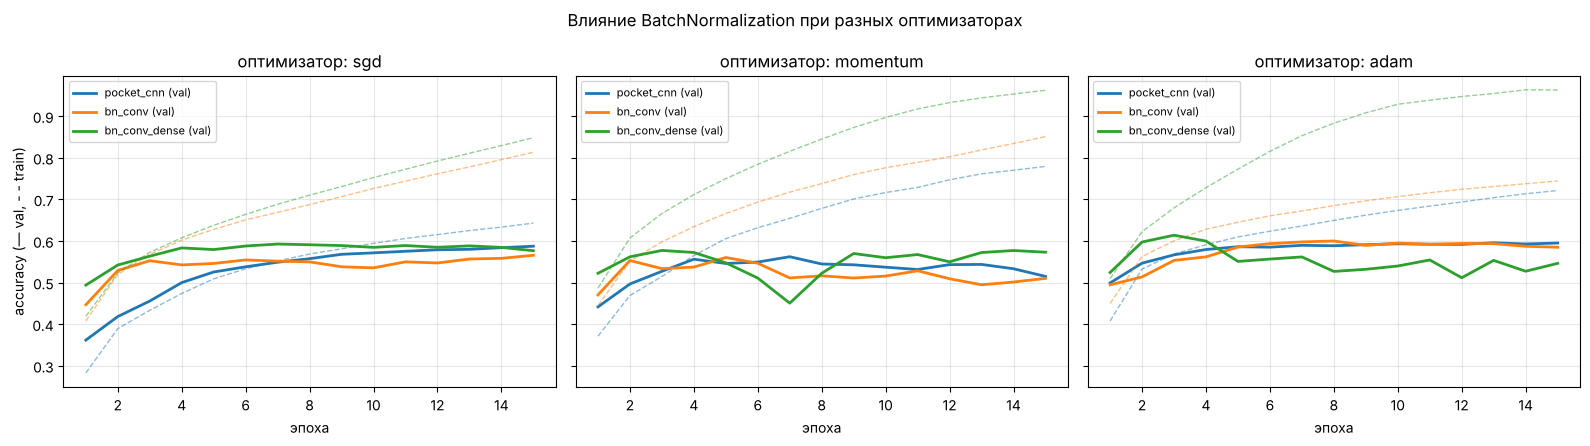

Accuracy на тесте (строки — модель, столбцы — оптимизатор):


,sgd,momentum,adam
pocket_cnn,0.5817,0.5177,0.5822
bn_conv,0.5640,0.5054,0.5805
bn_conv_dense,0.5701,0.5645,0.5377


In [27]:
grid_hist = {**evaluator.histories, **evaluator_bn.histories}
grid_scores = {**scores_opt, **scores_bn}
grid_times = {**evaluator.times, **evaluator_bn.times}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for a, opt in zip(ax, optimizers):
    for i, m in enumerate(builders):
        h = grid_hist[f'{m}_{opt}']
        ep = np.arange(1, len(h['val_accuracy']) + 1)
        a.plot(ep, h['val_accuracy'], c=f'C{i}', lw=2, label=f'{m} (val)')
        a.plot(ep, h['accuracy'], c=f'C{i}', lw=1, ls='--', alpha=.5)
    a.set(title=f'оптимизатор: {opt}', xlabel='эпоха'); a.grid(alpha=.3); a.legend(fontsize=8)
    a.xaxis.set_major_locator(MaxNLocator(integer=True))
ax[0].set_ylabel('accuracy (— val, - - train)')
plt.suptitle('Влияние BatchNormalization при разных оптимизаторах'); plt.tight_layout()
plt.savefig('images/1_4_batchnorm.png', dpi=110, bbox_inches='tight'); plt.show()

test_table = pd.DataFrame({opt: {m: grid_scores[f'{m}_{opt}'] for m in builders} for opt in optimizers})
for k, v in scores_bn.items():
    RESULTS[f'1.4 {k}'] = v
print('Accuracy на тесте (строки — модель, столбцы — оптимизатор):')
test_table.round(4)

Прокомментируйте полученные результаты.

**Комментарий к 1.4.**
* **BatchNormalization ускоряет обучение**, особенно для SGD: 55 % на валидации достигается за 3 эпохи вместо 8, а лучшая точность у `bn_conv_dense` + SGD — уже на 7-й эпохе вместо 15-й. С momentum — за 2 эпохи вместо 4.
* **Максимум всей сетки** — `bn_conv_dense` + Adam: **0,614** на валидации на 3-й эпохе (без нормализации — 0,595).
* **Но без регуляризации BN ускоряет и переобучение.** Train-точность `bn_conv_dense` с momentum и Adam уходит к 0,96, а валидация после пика падает: разрыв train − val у `bn_conv_dense` + Adam к 15-й эпохе 0,42. Поэтому на тесте по весам последней эпохи результат хуже базового (0,538 против 0,582). BN здесь работает как ускоритель, а не как регуляризатор — ему нужна ранняя остановка или dropout/аугментация.
* Нормализация только после свёртки (10 каналов) почти ничего не меняет: с Adam 0,600 против 0,595, с SGD даже ниже базы. Основной эффект даёт BN в полносвязном слое на 100 нейронов.
* На CPU эпоха с BN дольше примерно в 1,5 раза (129–139 с на 15 эпох против 77–91 с): для крошечной сети дополнительный слой заметен.

**Задание 1.5 (опционально)** Посмотрите на batch_size (параметр model.fit) - при большем батче модель будет быстрее проходить эпохи, но с совсем огромным батчом вам потребуется больше эпох для сходимости (т.к. сеть делает меньше шагов за одну эпоху).
Найдите такое значение, при котором модель быстрее достигает точности 55%. **Hint**: используйте early stopping callback.

**Как меряем.** Берём лучшую по валидации комбинацию «модель + оптимизатор» из сетки 1.3–1.4 и обучаем её заново с разными `batch_size`. Колбэк `TimeToTarget` засекает время от начала обучения до эпохи, на которой `val_accuracy` впервые достигла 55 %, и останавливает обучение (это и есть «ранняя остановка» по достижению цели). `EarlyStopping(patience=3)` страхует от бесконечного обучения, если цель не достигается. Время включает проход по валидации в конце каждой эпохи, поэтому точность замера — одна эпоха.

In [28]:
class TimeToTarget(keras.callbacks.Callback):
    '''Останавливает обучение, когда val_accuracy >= target, и запоминает время и номер эпохи.'''
    def __init__(self, target=0.55):
        super().__init__()
        self.target = target

    def on_train_begin(self, logs=None):
        self.t0, self.epoch, self.seconds = time.perf_counter(), None, None

    def on_epoch_end(self, epoch, logs=None):
        if logs['val_accuracy'] >= self.target:
            self.epoch, self.seconds = epoch + 1, time.perf_counter() - self.t0
            self.model.stop_training = True


make_optimizer = {'sgd': lambda: O.SGD(), 'momentum': lambda: O.SGD(momentum=0.9), 'adam': lambda: O.Adam()}

best_key = max(grid_hist, key=lambda k: max(grid_hist[k]['val_accuracy']))
bs_model_name, bs_opt_name = best_key.rsplit('_', 1)
print(f'Модель: {bs_model_name}, оптимизатор: {bs_opt_name}\n')

bs_rows = []
for bs in [16, 32, 64, 128, 256, 512, 1024]:
    keras.utils.set_random_seed(42)
    m = builders[bs_model_name]()
    m.compile(optimizer=make_optimizer[bs_opt_name](), loss='categorical_crossentropy', metrics=['accuracy'])
    target_cb = TimeToTarget(0.55)
    t0 = time.perf_counter()
    h = m.fit(X_train, y_train, batch_size=bs, epochs=40, validation_data=(X_val, y_val), verbose=0,
              callbacks=[target_cb, keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3)])
    total = time.perf_counter() - t0
    n_ep = len(h.history['loss'])
    bs_rows.append({'batch_size': bs, 'шагов за эпоху': int(np.ceil(len(X_train) / bs)),
                    'с/эпоху': total / n_ep, 'эпох до 55%': target_cb.epoch,
                    'время до 55%, с': target_cb.seconds, 'max val_acc': max(h.history['val_accuracy'])})
    print(f"batch {bs:>4}: эпох до 55%: {target_cb.epoch}, время: "
          f"{'—' if target_cb.seconds is None else f'{target_cb.seconds:.1f} с'}", flush=True)

bs_table = pd.DataFrame(bs_rows).set_index('batch_size')
bs_table.round(3)

Модель: bn_conv_dense, оптимизатор: adam



batch   16: эпох до 55%: 1, время: 13.9 с


batch   32: эпох до 55%: 2, время: 17.9 с


batch   64: эпох до 55%: 1, время: 7.5 с


batch  128: эпох до 55%: 4, время: 26.6 с


batch  256: эпох до 55%: 5, время: 22.9 с


batch  512: эпох до 55%: None, время: —


batch 1024: эпох до 55%: None, время: —


,шагов за эпоху,с/эпоху,эпох до 55%,"время до 55%, с",max val_acc
batch_size,,,,,
16,2500,21.722,1.0,13.887,0.581
32,1250,9.103,2.0,17.884,0.597
64,625,7.902,1.0,7.523,0.555
128,313,6.785,4.0,26.640,0.589
256,157,4.835,5.0,22.906,0.579
512,79,4.731,NaN,NaN,0.524
1024,40,5.153,NaN,NaN,0.239


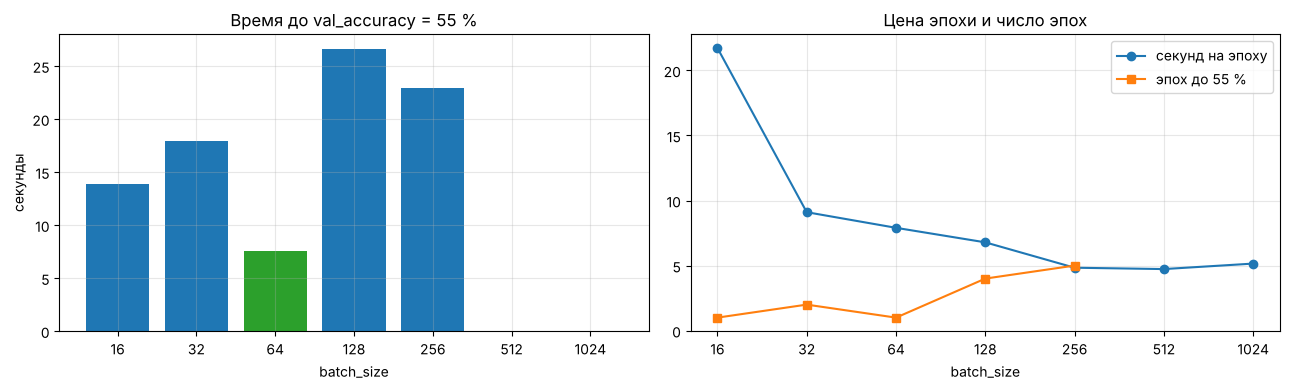

Быстрее всего 55 % достигается при batch_size = 64


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
t = pd.to_numeric(bs_table['время до 55%, с'])
ax[0].bar(t.index.astype(str), t.fillna(0), color=['C2' if v == t.min() else 'C0' for v in t])
ax[0].set(title='Время до val_accuracy = 55 %', xlabel='batch_size', ylabel='секунды')
ax[1].plot(bs_table.index.astype(str), bs_table['с/эпоху'], 'o-', label='секунд на эпоху')
ax[1].plot(bs_table.index.astype(str), pd.to_numeric(bs_table['эпох до 55%']), 's-', label='эпох до 55 %')
ax[1].set(title='Цена эпохи и число эпох', xlabel='batch_size'); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('images/1_5_batch_size.png', dpi=110, bbox_inches='tight'); plt.show()
if t.notna().any():
    print('Быстрее всего 55 % достигается при batch_size =', int(t.idxmin()))
else:
    print('Ни один batch_size не достиг 55 % за отведённые эпохи')

**Вывод по 1.5.** Быстрее всего 55 % достигается при **batch_size = 64**: одна эпоха, **7,5 с**.
* При батче 16 цель тоже берётся за одну эпоху, но эпоха из 2500 шагов идёт почти вдвое дольше (13,9 с против 7,5 с). При батче 32 нужно 2 эпохи (17,9 с).
* С ростом батча эпоха дешевеет (с 21,7 до ~4,8 с) только до 256, дальше CPU уже загружен полностью. Зато шагов за эпоху всё меньше (с 2500 до 40), и эпох до цели нужно больше: 4 эпохи при 128 (26,6 с), 5 при 256 (22,9 с).
* При 512 и 1024 цель не достигнута: максимум 0,524 и 0,239, после чего `EarlyStopping(patience=3)` остановил обучение. За эпоху всего 79 и 40 обновлений весов, а скользящие статистики BatchNormalization (momentum 0,99) за такое число шагов не успевают установиться, поэтому валидация в первые эпохи низкая и нестабильная. Это ровно эффект из условия: с огромным батчом нужно больше эпох.
* Замер сделан на CPU и с точностью до эпохи. На GPU большие батчи обрабатываются почти так же быстро, как маленькие, поэтому оптимум там ожидаемо сместится в сторону больших значений.

**Задание 1.6 (опционально)** Попробуйте найти такую комбинацию метода обучения и нормализации, при которой сеть имеет наилучшую кривую обучения. Поясните, что вы понимаете под "наилучшей" кривой обучения.

**Что считаю «наилучшей» кривой обучения.** Кривая валидационной точности, которая
1. **быстро растёт** — мало эпох до заданного уровня (55 %);
2. **высоко выходит на плато** — максимальная `val_accuracy`;
3. **устойчива** — без провалов и без большого разрыва между train и val (нет переобучения).

Первые два пункта вместе хорошо описывает **средняя `val_accuracy` по всем эпохам** — по сути площадь под кривой (AUC): она больше у кривой, которая и растёт быстро, и держится высоко. По ней и ранжирую, а разрыв train − val в конце обучения смотрю как ограничение.

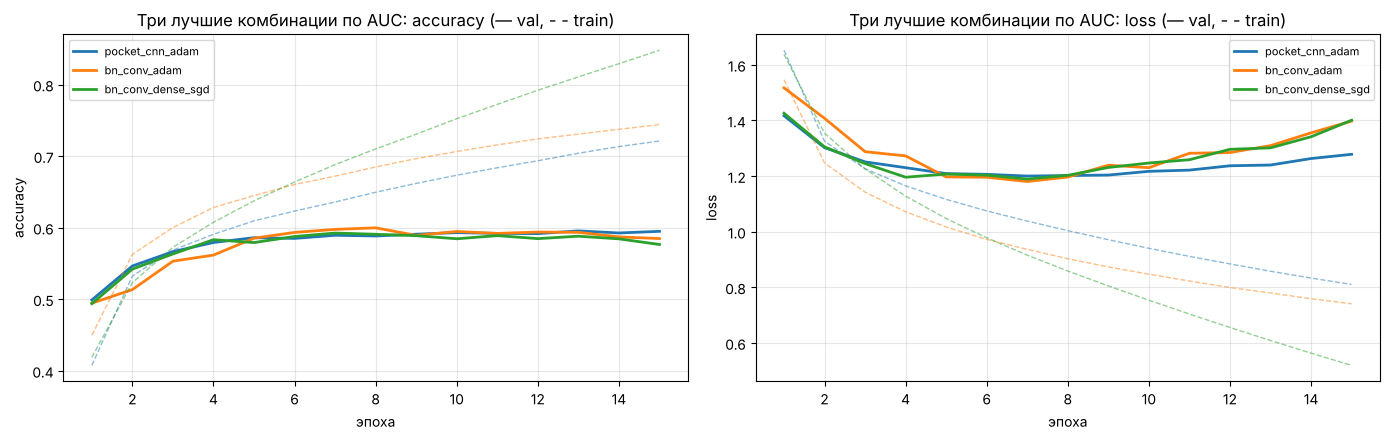

,best val_acc,эпоха best,эпох до 55%,mean val_acc (AUC),train−val в конце,test_acc,"время, с"
прогон,,,,,,,
pocket_cnn_adam,0.595,13,3,0.579,0.126,0.582,91.0
bn_conv_adam,0.600,8,3,0.576,0.159,0.580,138.0
bn_conv_dense_sgd,0.592,7,3,0.575,0.271,0.570,132.0
bn_conv_dense_adam,0.614,3,2,0.553,0.417,0.538,139.0
bn_conv_dense_momentum,0.577,3,2,0.549,0.389,0.564,129.0
bn_conv_sgd,0.566,15,3,0.541,0.248,0.564,133.0
pocket_cnn_momentum,0.562,7,4,0.531,0.264,0.518,87.0
pocket_cnn_sgd,0.587,15,8,0.530,0.056,0.582,77.0
bn_conv_momentum,0.560,5,2,0.520,0.341,0.505,134.0


In [30]:
stats_grid = curve_stats(grid_hist)
stats_grid['test_acc'] = pd.Series(grid_scores)
stats_grid['время, с'] = pd.Series(grid_times).round(0)
stats_grid = stats_grid.sort_values('mean val_acc (AUC)', ascending=False)

top = stats_grid.index[:3]
plot_curves({k: grid_hist[k] for k in top}, 'Три лучшие комбинации по AUC', fname='1_6_best_curves.png')
stats_grid.round(3)

**Вывод по 1.6.** По средней `val_accuracy` (AUC) тройка лидеров:
1. **Adam без нормализации** — AUC 0,579, лучшая точность 0,595, разрыв train − val 0,13;
2. **Adam + BN после свёртки** — AUC 0,576, лучшая точность 0,600 уже на 8-й эпохе (без BN — на 13-й), разрыв 0,16;
3. **SGD + BN в свёртке и Dense** — AUC 0,575, 55 % за 3 эпохи, но разрыв уже 0,27.

Самую высокую и быструю кривую даёт **Adam + BN в свёртке и Dense** (0,614 на 3-й эпохе), но после пика она падает из-за переобучения (разрыв 0,42), и по площади под кривой комбинация только 4-я.

Итого: при фиксированном числе эпох без ранней остановки наилучшая кривая у **Adam** (без BN или с BN в свёртке) — быстрый рост и устойчивое плато. Если обучение останавливать на лучшей эпохе, выигрывает **Adam + BN в свёртке и Dense** — максимум качества за минимум эпох; поэтому она и взята в 1.5. Momentum с параметрами по умолчанию нигде не лучший: в каждой модели его обгоняет Adam, а BN после свёртки + momentum — худшая комбинация по AUC (0,520). Главный вывод для следующего задания: адаптивный оптимизатор и BN дают быстрый рост, а чтобы кривая не падала, к ним нужна регуляризация.

## Свёрточная нейросеть здорового человека

**Задание 1.7 (обязательно попытаться)** Наигравшись выше, обучим большую свёрточную сеть, которая даст на тестовой выборке __accuracy больше 80%__. В этом задании вам потребуется провести эксперименты, сравнив их между собой в конце. Возможно, может быть несколько проще, если писать выводы во время или сразу после каждого эксперимента, после чего сделать общие выводы.

Рекомендуем начать с лучшей модели предыдущего задания и постепенно её улучшать. Вы можете использовать всё, что угодно: любые активации, сколь угодно большие свёрточные слои и глубокие сети. Единственное ограничение: __нельзя использовать предобученные сети и дополнительные данные__.

### Полезные советы
* Для начала, неплохо бы научить что-нибудь побольше, чем 10 фильтров 3x3.
* __Главное правило: одно изменение на эксперимент__. Если у вас есть 2 идеи по улучшению сети, сначала попробуйте их независимо. Может оказаться, что одно из них дало __+10%__ точности а другое __-7%__. А вы так и будете думать, что сделали 2 полезных изменения которые в сумме дают __+3%__. Если какая-то идея не работает — даже если она вам нравится - опишите ее и выкидывайте из дальнейших экспериментов.
* __Be careful or you will dropout__. Дропаут (`L.Dropout`) может позволить вам обучить в несколько раз бОльшую сеть без переобучения, выжав несколько процентов качества. Это круто, но не стоит сразу ставить dropout 50%. Во-первых, слишком сильный дропаут только ухудшит сеть (underfitting). Во-вторых, даже если дропаут улучшает качество, он замедляет обучение. Рекомендуем начинать с небольшого дропаута, быстро провести основные эксперименты, а потом жахнуть в 2 раза больше нейронов и дропаута ~~на ночь~~.
* __Аугментация данных__. Если котика слегка повернуть и подрезать (простите), он всё равно останется котиком. А в керасе есть [удобный класс](https://keras.io/preprocessing/image/), который поставит подрезание котиков на поток. Ещё можно сделать этот трюк в тесте: вертим картинку 10 раз, предсказываем вероятности и усредняем. Только один совет: прежде, чем учить, посмотрите глазами на аугментированные картинки. Если вы сами не можете их различить, то и сеть не сможет.
* __Don't just stack more layers__. Есть более эффективные способы организовать слои, чем простой Sequential. Вот пара идей: [Inception family](https://hacktilldawn.com/2016/09/25/inception-modules-explained-and-implemented/), [ResNet family](https://towardsdatascience.com/an-overview-of-resnet-and-its-variants-5281e2f56035?gi=9018057983ca), [Densely-connected convolutions](https://arxiv.org/abs/1608.06993). Только не копируйте архитектуру подчистую — вам скорее всего хватит меньшего размера.
* __Долго != плохо__. Более глубокие архитектуры обычно требуют бОльше эпох до сходимости. Это значит, что в первые несколько эпох они могут быть хуже менее глубоких аналогов. Дайте им время, запаситесь чаем и обмажьтесь batch-norm-ом.

**Подготовка данных.** В заготовке `split = 45000`, но после выделения валидации в `X_train` всего 40 000 картинок — валидационная часть `X_train[45000:]` оказалась бы пустой. Поэтому используем уже отложенную `X_val`.

Аугментацию вместо `ImageDataGenerator` (в Keras 3 он устаревший и медленный) делаем слоями Keras внутри модели: отражение по горизонтали и сдвиг до 4 пикселей (12,5 %) с отражением краёв. Слои работают только при обучении, на предсказании отключаются, и считаются на GPU вместе с сетью. Сначала смотрим на результат глазами.

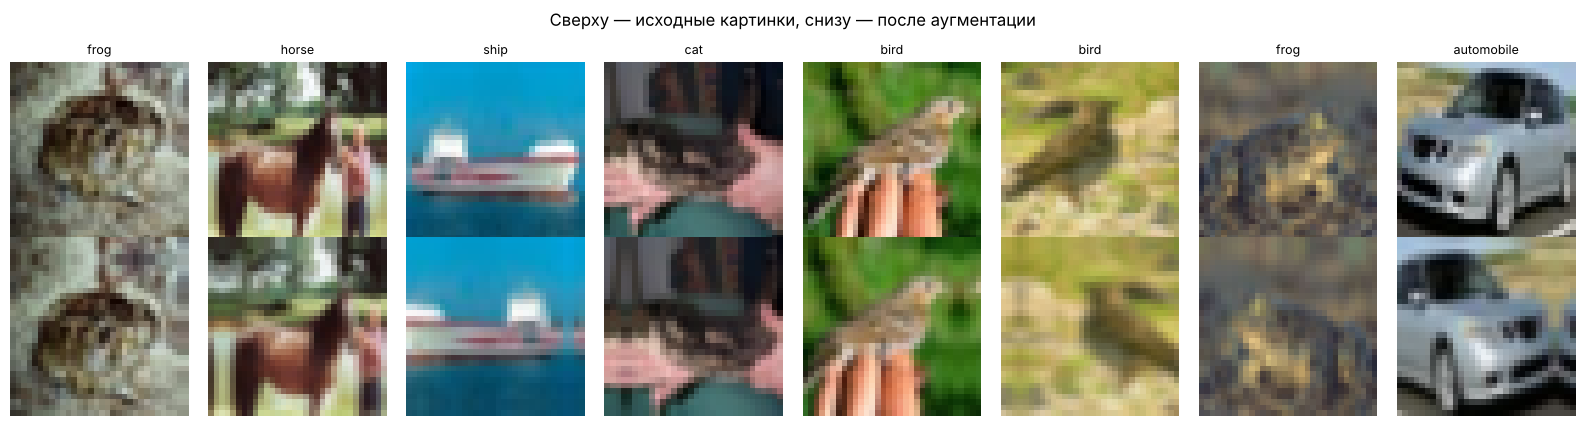

In [31]:
def make_augment():
    return keras.Sequential([L.RandomFlip('horizontal'),
                             L.RandomTranslation(0.125, 0.125, fill_mode='reflect')], name='augment')

augment = make_augment()
sample = X_train[:8]
plt.figure(figsize=[16, 4.3])
for i in range(8):
    plt.subplot(2, 8, i + 1); plt.imshow(sample[i]); plt.axis('off')
    plt.title(class_names[y_train[i].argmax()], fontsize=9)
    aug_img = keras.ops.convert_to_numpy(augment(sample[i:i + 1], training=True)[0]).astype('float32')
    plt.subplot(2, 8, 9 + i); plt.imshow(np.clip(aug_img, 0, 1)); plt.axis('off')
plt.suptitle('Сверху — исходные картинки, снизу — после аугментации'); plt.tight_layout(); plt.show()

Котики остаются котиками, машины — машинами: аугментация не делает картинки неразличимыми.

### Эксперименты
Правило — **одно изменение на эксперимент**. Все короткие эксперименты: `Adam`, `batch_size=128`, одинаковое число эпох (`EPOCHS_EXP`), одинаковый seed.

| # | Модель | Что меняем относительно базы |
|---|---|---|
| E0 | лучшая карманная CNN из 1.6 | база, уже обучена |
| E1 | VGG-подобная сеть: 3 блока по 2 свёртки 3×3 (32-64-128 фильтров) + BN + max-pooling | глубина и ширина |
| E2 | E1 + аугментация | только аугментация |
| E3 | E1 + Dropout | только дропаут |
| E4 | E1 + аугментация + Dropout | объединяем то, что помогло |

Финальная модель — лучший вариант, обученный дольше со снижением learning rate на плато.

In [32]:
# Смешанная точность для больших сетей: на GPU — float16, на CPU с поддержкой bfloat16 (AMX / AVX512-BF16) — bfloat16.
# Веса хранятся во float32, выходной softmax считается во float32; на точность это практически не влияет,
# а обучение ускоряется в 2+ раза. Без подходящего железа остаётся обычный float32.
cpu_flags = open('/proc/cpuinfo').read() if os.path.exists('/proc/cpuinfo') else ''
if tf.config.list_physical_devices('GPU'):
    keras.mixed_precision.set_global_policy('mixed_float16')
elif 'avx512_bf16' in cpu_flags or 'amx_bf16' in cpu_flags:
    keras.mixed_precision.set_global_policy('mixed_bfloat16')
print('Политика вычислений:', keras.mixed_precision.global_policy().name)


def build_vgg(width=32, dropout=0.0, augment=False, name='vgg'):
    '''VGG-подобная сеть: 3 блока [Conv-BN-ReLU] x 2 + MaxPool, затем Dense-голова.
    dropout > 0 — дропаут после каждого блока (растёт к выходу) и перед выходным слоем.'''
    layers = [L.Input(shape=(32, 32, 3))]
    if augment:
        layers.append(make_augment())
    for i, filters in enumerate((width, 2 * width, 4 * width)):
        for _ in range(2):
            layers += [L.Conv2D(filters, 3, padding='same', use_bias=False),
                       L.BatchNormalization(), L.Activation('relu')]
        layers.append(L.MaxPooling2D())
        if dropout:
            layers.append(L.Dropout(dropout + 0.1 * i))
    layers += [L.Flatten(), L.Dense(4 * width, use_bias=False), L.BatchNormalization(), L.Activation('relu')]
    if dropout:
        layers.append(L.Dropout(dropout + 0.3))
    layers.append(L.Dense(10, activation='softmax', dtype='float32'))
    return keras.Sequential(layers, name=name)


exp_hist, exp_scores, exp_times = {}, {}, {}

def run_experiment(name, model, epochs=EPOCHS_EXP, batch_size=128, callbacks=()):
    keras.utils.set_random_seed(42)
    model.compile(optimizer=O.Adam(), loss='categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, verbose=0,
                  validation_data=(X_val, y_val), callbacks=list(callbacks))
    exp_hist[name], exp_times[name] = h.history, time.time() - t0
    exp_scores[name] = accuracy_score(y_test.ravel(), model.predict(X_test, verbose=0).argmax(1))
    va, ta = h.history['val_accuracy'], h.history['accuracy']
    print(f'{name:<24} params: {model.count_params():>9,}  время: {exp_times[name]:5.0f} с  '
          f'best val: {max(va):.4f}  train−val в конце: {ta[-1] - va[-1]:+.3f}  test: {exp_scores[name]:.4f}',
          flush=True)
    return model

# E0 — лучшая карманная сеть из 1.6 (уже обучена в сетке)
e0 = stats_grid.index[0]
exp_hist[f'E0 {e0}'] = grid_hist[e0]; exp_scores[f'E0 {e0}'] = grid_scores[e0]; exp_times[f'E0 {e0}'] = grid_times[e0]
print(f"E0 {e0}: best val {max(grid_hist[e0]['val_accuracy']):.4f}, test {grid_scores[e0]:.4f}  (из сетки 1.6)")

Политика вычислений: mixed_bfloat16
E0 pocket_cnn_adam: best val 0.5955, test 0.5822  (из сетки 1.6)


In [33]:
build_vgg(name='E1').summary()
_ = run_experiment('E1 VGG+BN', build_vgg(name='E1'))

Model: "E1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_21 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_22 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_23 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_24 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_25 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 2048)           │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

E1 VGG+BN                params:   552,298  время:   635 с  best val: 0.7370  train−val в конце: +0.264  test: 0.7018


In [34]:
_ = run_experiment('E2 VGG+BN+aug', build_vgg(augment=True, name='E2'))

E2 VGG+BN+aug            params:   552,298  время:   650 с  best val: 0.8016  train−val в конце: +0.085  test: 0.7404


In [35]:
_ = run_experiment('E3 VGG+BN+dropout', build_vgg(dropout=0.2, name='E3'))

E3 VGG+BN+dropout        params:   552,298  время:   718 с  best val: 0.7707  train−val в конце: +0.018  test: 0.7632


In [36]:
_ = run_experiment('E4 VGG+BN+aug+dropout', build_vgg(dropout=0.2, augment=True, name='E4'))

E4 VGG+BN+aug+dropout    params:   552,298  время:   702 с  best val: 0.7637  train−val в конце: -0.009  test: 0.7330


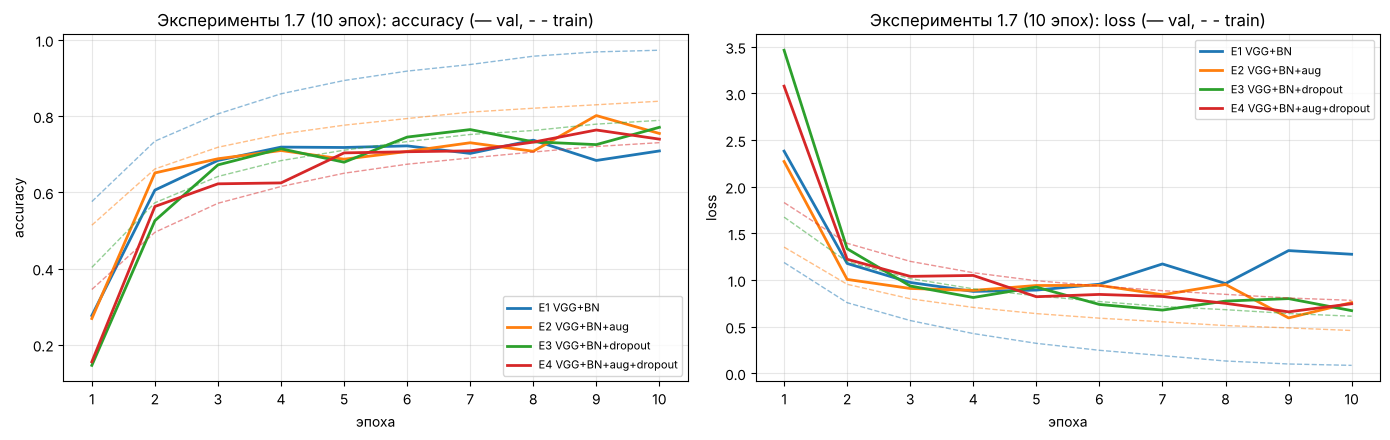

,best val_acc,эпоха best,train−val в конце,test_acc,"время, с"
прогон,,,,,
E0 pocket_cnn_adam,0.595,13,0.126,0.582,91.0
E1 VGG+BN,0.737,8,0.264,0.702,635.0
E2 VGG+BN+aug,0.802,9,0.085,0.740,650.0
E3 VGG+BN+dropout,0.771,10,0.018,0.763,718.0
E4 VGG+BN+aug+dropout,0.764,9,-0.009,0.733,702.0


In [37]:
plot_curves({k: v for k, v in exp_hist.items() if not k.startswith('E0')},
            f'Эксперименты 1.7 ({EPOCHS_EXP} эпох)', fname='1_7_experiments.png')
exp_table = curve_stats(exp_hist)[['best val_acc', 'эпоха best', 'train−val в конце']]
exp_table['test_acc'] = pd.Series(exp_scores)
exp_table['время, с'] = pd.Series(exp_times).round(0)
exp_table.round(3)

**Выводы по экспериментам** (10 эпох, Adam, batch 128; test — по весам последней эпохи):
* **E1, глубина и ширина:** лучшая val_accuracy 0,737 — на 14 п.п. выше карманной сети (0,595). Но к 10-й эпохе train ≈ 0,97 при val ≈ 0,71, а `val_loss` после 5-й эпохи растёт: сильное переобучение (разрыв 0,26).
* **E2, + аугментация:** лучшая val_accuracy **0,802** (+6,5 п.п. к E1), разрыв сократился до 0,085. Самый большой выигрыш от одного изменения.
* **E3, + dropout:** 0,771 (+3,4 п.п.), разрыв всего 0,018; лучшая точность пришлась на последнюю эпоху, поэтому и test по последней эпохе лучший среди коротких прогонов (0,763).
* **E4, аугментация + dropout:** 0,764 — за 10 эпох ниже, чем E2, а train даже немного ниже val (разрыв −0,009). Два регуляризатора вместе замедляют обучение: за 10 эпох модель не успевает обучиться, но и не переобучается.

Оба изменения по отдельности полезны. Нулевой разрыв у E4 означает, что её можно учить заметно дольше без переобучения, поэтому финальная модель — архитектура E4 с длинным обучением. Сравнить E2 и E4 на длинной дистанции бюджет времени не позволил, поэтому выбор E4 опирается на отсутствие переобучения у неё, а не на прямое сравнение.

Ещё одно наблюдение: при постоянном lr = 0,001 валидация сильно скачет (у E2 — с 0,80 до 0,76 на последней эпохе). Поэтому в финальном обучении learning rate снижается на плато, а `EarlyStopping` возвращает лучшие веса.

### Финальная модель
Берём архитектуру E4: VGG-подобная сеть 32-64-128 фильтров, BatchNormalization, аугментация, Dropout 0,2 / 0,3 / 0,4 после блоков и 0,5 перед выходом. Обучаем до 40 эпох: Adam (lr = 0,001), `ReduceLROnPlateau` уменьшает lr в 3,3 раза, если `val_loss` не улучшается 3 эпохи, `EarlyStopping(patience=8)` возвращает лучшие веса. Ширину оставляем 32 фильтра: так обучение укладывается в бюджет времени, а запас до 80 % уже большой.

In [38]:
## Финальная модель: архитектура E4, ширина 32-64-128 фильтров
final_model = build_vgg(width=32, dropout=0.2, augment=True, name='final_vgg')
final_model.summary()

Model: "final_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augment (Sequential)            │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_52          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_55 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_53          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_56 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_54          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_57 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_55          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_58 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_59 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_57          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [39]:
final_callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
                   tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-5,
                                                        verbose=1),
                   tf.keras.callbacks.ModelCheckpoint('checkpoints/final_best.keras', monitor='val_accuracy',
                                                      save_best_only=True)]

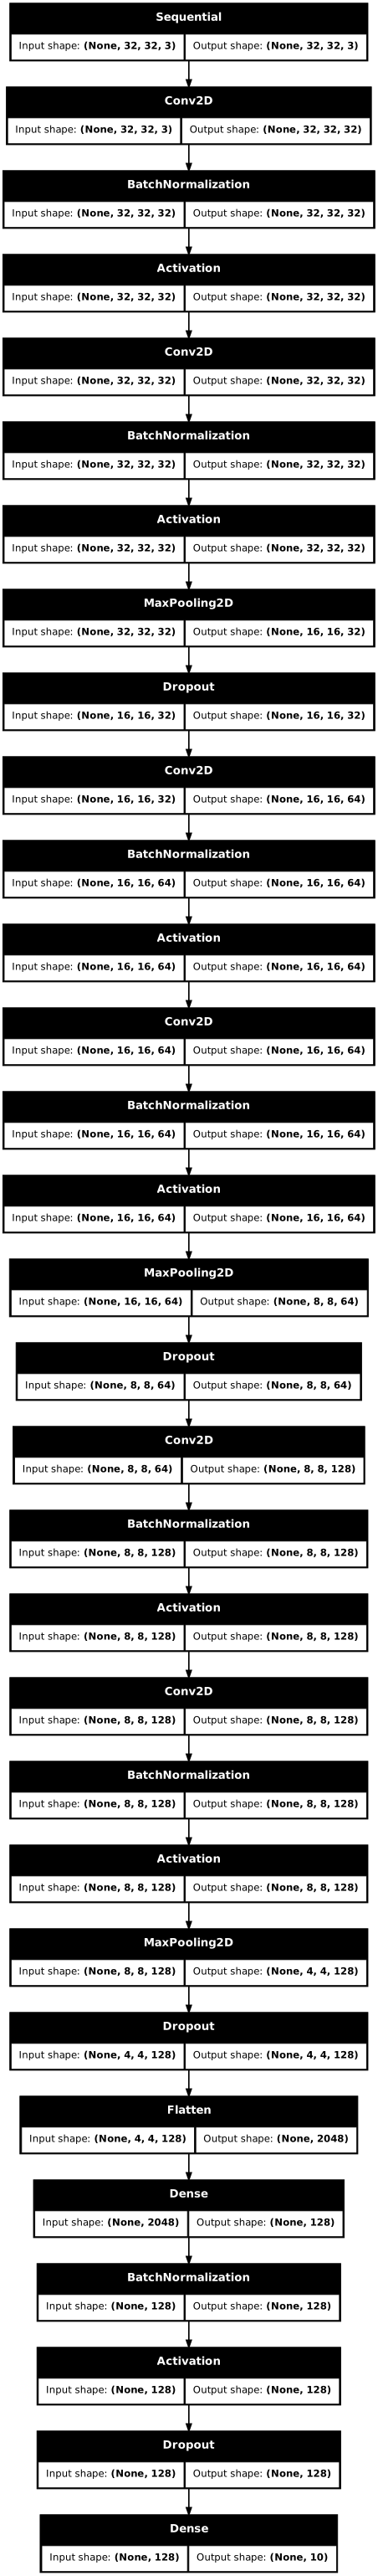

In [40]:
try:
    tf.keras.utils.plot_model(final_model, 'images/final_model.png', show_shapes=True, dpi=60)
    from IPython.display import Image, display
    display(Image('images/final_model.png'))
except Exception as e:      # нужен graphviz; без него просто пропускаем картинку
    print('plot_model недоступен:', e)

In [41]:
keras.utils.set_random_seed(42)
final_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                    loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
history_final = final_model.fit(X_train, y_train, batch_size=128, epochs=EPOCHS_FINAL,
                                validation_data=(X_val, y_val), callbacks=final_callbacks, verbose=2)
print(f"Обучение: {(time.time() - t0) / 60:.1f} мин, эпох: {len(history_final.history['loss'])}")

Epoch 1/40


313/313 - 56s - 179ms/step - accuracy: 0.3451 - loss: 1.8305 - val_accuracy: 0.1552 - val_loss: 3.0786 - learning_rate: 0.0010


Epoch 2/40


313/313 - 78s - 248ms/step - accuracy: 0.4951 - loss: 1.3939 - val_accuracy: 0.5629 - val_loss: 1.2225 - learning_rate: 0.0010


Epoch 3/40


...

Epoch 39/40


313/313 - 81s - 257ms/step - accuracy: 0.8473 - loss: 0.4491 - val_accuracy: 0.8671 - val_loss: 0.3883 - learning_rate: 2.7000e-05


Epoch 40/40


313/313 - 84s - 268ms/step - accuracy: 0.8452 - loss: 0.4513 - val_accuracy: 0.8696 - val_loss: 0.3888 - learning_rate: 2.7000e-05


Обучение: 43.7 мин, эпох: 40


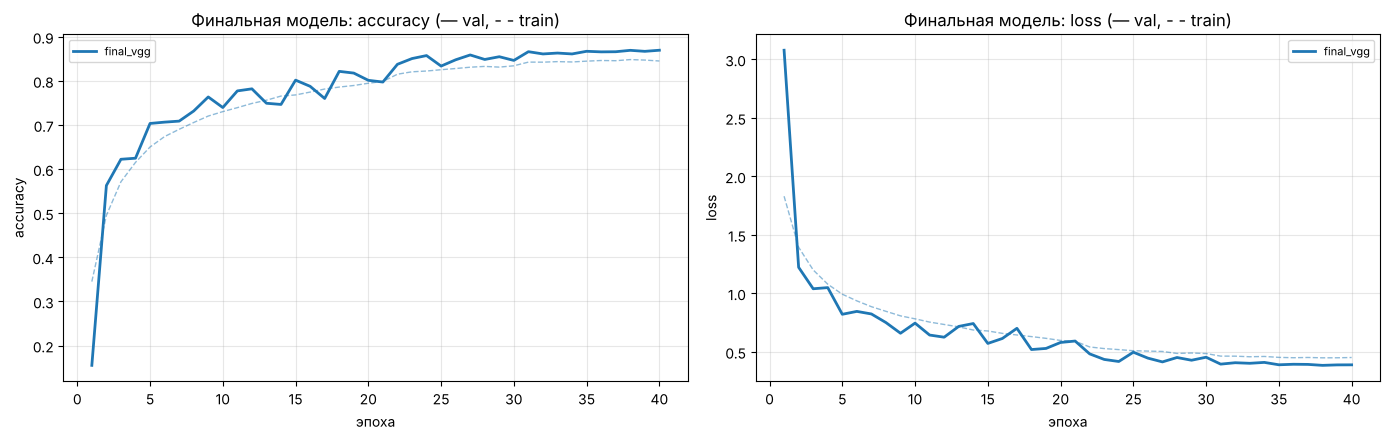

In [42]:
plot_curves({'final_vgg': history_final}, 'Финальная модель', fname='1_7_final.png')

Момент истины: проверьте, какого качества достигла ваша сеть.

In [43]:
from sklearn.metrics import accuracy_score

predict_x=final_model.predict(X_test)
classes_x=np.argmax(predict_x,axis=1)

test_acc = accuracy_score(y_test, classes_x)
print("\n Test_acc =", test_acc)
if test_acc > 0.8:
    print("Это победа!")
RESULTS['1.7 Финальная VGG-сеть'] = test_acc

  1/313 ━━━━━━━━━━━━━━━━━━━━ 35s 113ms/step

  6/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step  

 11/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step

 16/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step

 21/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step

...

301/313 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

308/313 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step



 Test_acc = 0.8576
Это победа!


**Бонус: усреднение предсказаний по аугментациям на тесте (TTA).** Предсказываем вероятности для исходной картинки и её зеркального отражения и усредняем — совет из условия задания. Основной результат выше — без TTA.

Test_acc без TTA = 0.8576, с TTA (оригинал + отражение) = 0.8643


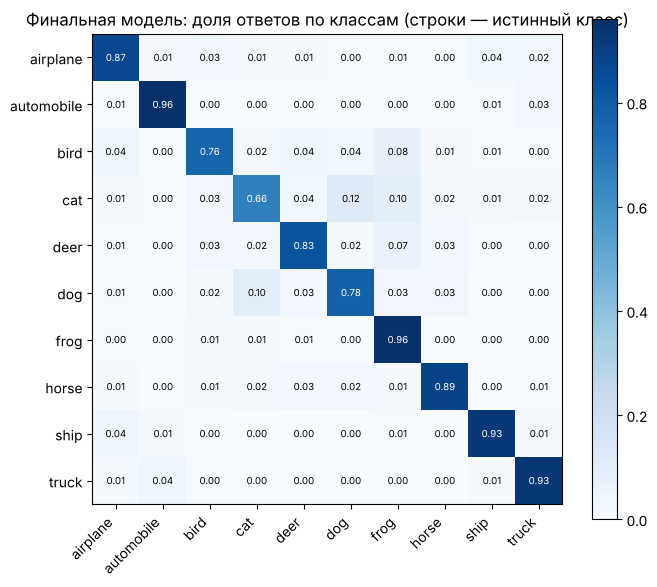

Точность по классам: airplane 0.873, automobile 0.957, bird 0.764, cat 0.663, deer 0.826, dog 0.784, frog 0.961, horse 0.886, ship 0.929, truck 0.933


In [44]:
p_tta = (final_model.predict(X_test, verbose=0) + final_model.predict(X_test[:, :, ::-1], verbose=0)) / 2
test_acc_tta = accuracy_score(y_test.ravel(), p_tta.argmax(1))
print(f'Test_acc без TTA = {test_acc:.4f}, с TTA (оригинал + отражение) = {test_acc_tta:.4f}')
RESULTS['1.7 Финальная VGG-сеть + TTA'] = test_acc_tta

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test.ravel(), classes_x, normalize='true')
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha='right'); plt.yticks(range(10), class_names)
for i in range(10):
    for j in range(10):
        plt.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                 color='white' if cm[i, j] > .5 else 'black')
plt.title('Финальная модель: доля ответов по классам (строки — истинный класс)')
plt.tight_layout(); plt.savefig('images/1_7_confusion.png', dpi=110, bbox_inches='tight'); plt.show()
print('Точность по классам:', ', '.join(f'{n} {a:.3f}' for n, a in zip(class_names, cm.diagonal())))

А теперь, опишите свои <s>ощущения</s> результаты от проведенных экспериментов.

In [45]:
summary = pd.Series(RESULTS, name='accuracy на тесте').to_frame()
summary.round(4)

,accuracy на тесте
"1.1 Полносвязная сеть, SGD",0.4937
"1.2 Карманная CNN, SGD",0.5863
1.3 pocket_cnn_sgd,0.5817
1.3 pocket_cnn_momentum,0.5177
1.3 pocket_cnn_adam,0.5822
1.4 bn_conv_sgd,0.5640
1.4 bn_conv_momentum,0.5054
1.4 bn_conv_adam,0.5805
1.4 bn_conv_dense_sgd,0.5701
1.4 bn_conv_dense_momentum,0.5645


### Итоги

| Задание | Модель | Accuracy на тесте |
|---|---|---|
| 1.1 | Полносвязная сеть, SGD | 49,37 % (порог 45 %) |
| 1.2 | Карманная CNN, SGD | 58,63 % (порог 50 %) |
| 1.3 | Карманная CNN, лучший оптимизатор — Adam | 58,22 % |
| 1.7 | VGG-подобная сеть + BN + аугментация + dropout | **85,76 %** (порог 80 %) |
| 1.7 | то же + TTA (оригинал + отражение) | **86,43 %** |

**Что показали эксперименты**
* **Свёртки важнее числа параметров.** Карманная CNN в 7,5 раза меньше полносвязной сети и точнее на 9 п.п.
* **Оптимизатор.** С параметрами по умолчанию лучший Adam: быстрее всех растёт и выше всех держится. SGD устойчив, но медленный. Momentum при lr = 0,01 слишком агрессивен для маленькой сети и быстро переобучается.
* **BatchNormalization** — ускоритель: с SGD 55 % за 3 эпохи вместо 8, лучший пик сетки 0,614. Но вместе с обучением ускоряется и переобучение, поэтому BN нужно сочетать с регуляризацией.
* **batch_size.** На CPU быстрее всего до 55 % доходит батч 64 (7,5 с). Слишком большой батч (512+) делает мало шагов за эпоху и не успевает дойти до цели.
* **Большая сеть.** Самый большой прирост дали глубина и ширина (+14 п.п. на валидации к карманной сети) и аугментация (+6,5 п.п. и в 3 раза меньший разрыв train − val). Dropout дополнительно убирает переобучение.
* **Снижение learning rate на плато** заметно поднимает качество: после первого снижения (21-я эпоха) val_accuracy выросла с 0,798 до 0,838, после второго (30-я) — с 0,847 до 0,866. Итог на валидации — 0,870 на 40-й эпохе.
* **Где сеть ошибается.** Хуже всего распознаются кошки (66 %, чаще всего путаются с собаками — 12 %), птицы (76 %) и собаки (78 %). Лучше всего — лягушки и автомобили (96 %), корабли и грузовики (93 %).

**Что можно улучшить.** К концу обучения train-точность (0,845) ниже валидационной (0,870): регуляризация сильная, модель не упёрлась в потолок. Логичные следующие шаги — учить дольше, расширить сеть (64-128-256 фильтров), попробовать косинусное расписание lr и остаточные связи (ResNet-блоки) — каждый раз по одному изменению.